# Machine Learning (Perceptron and Logistic Regression)
## Task 1  (Prepare a Fair Experiment)

**Scenario:** A screening research team wants to compare two simple linear classifiers (Perceptron and Logistic Regression) on the *same* data.

**Dataset:** Pima Indians Diabetes Database (Kaggle, `diabetes.csv`), target column `Outcome` (0/1).
*Educational dataset — not a clinical decision tool.*

**Steps in this notebook**
1. Load the data
2. Inspect class balance and missing / invalid values
3. Treat invalid zeros (and justify)
4. Choose exactly two numeric predictors
5. Stratified 80/20 split (`random_state=42`)
6. Impute using **training-only** statistics
7. Standardize using **training-only** statistics
8. Verify, visualize and save the prepared data for Tasks 2–4
9. Explain why leakage would invalidate the comparison

## 0. Imports and Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 20)

## 1. Load the Data

Upload `diabetes.csv` to Colab (Files panel) or place it next to this notebook.
If the file is not found, the cell below tries to download a public copy automatically
(same Pima data; that copy has no header row, so column names are added).

In [2]:
import os

COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

if os.path.exists("diabetes.csv"):
    df = pd.read_csv("diabetes.csv")
    print("Loaded local diabetes.csv")
else:
    url = ("https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
           "pima-indians-diabetes.data.csv")
    df = pd.read_csv(url, header=None, names=COLS)
    print("Loaded public copy from GitHub")

print("Shape:", df.shape)
df.head()

Loaded public copy from GitHub
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Inspect the Data

In [3]:
df.info()
print()
print("Duplicate rows:", df.duplicated().sum())
print("Literal NaN values per column:\n", df.isna().sum(), sep="")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Duplicate rows: 0
Literal NaN values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPe

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### 2.1 Class balance

         count  proportion
Outcome                   
0          500       0.651
1          268       0.349


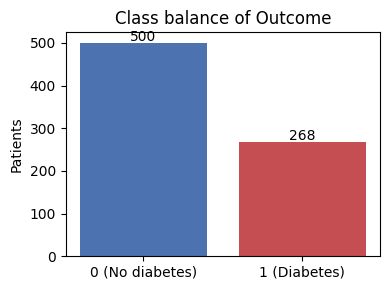

In [5]:
counts = df["Outcome"].value_counts().sort_index()
props = df["Outcome"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"count": counts, "proportion": props.round(3)}))

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["0 (No diabetes)", "1 (Diabetes)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_ylabel("Patients"); ax.set_title("Class balance of Outcome")
plt.tight_layout(); plt.show()

**Observation:** the classes are imbalanced (roughly 65% negative / 35% positive). A model that always predicts
"0" would already reach about 65% accuracy, so accuracy alone is a weak yardstick. This is also why we use a
**stratified** split, so that train and test keep the same class ratio.

### 2.2 Invalid zeros (hidden missing values)

In [6]:
zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_summary = pd.DataFrame({
    "zeros": (df[zero_invalid_cols] == 0).sum(),
    "percent": ((df[zero_invalid_cols] == 0).mean() * 100).round(2),
})
print(zero_summary)
print("\nPregnancies == 0 (valid, a woman can have zero pregnancies):", (df["Pregnancies"] == 0).sum())

               zeros  percent
Glucose            5     0.65
BloodPressure     35     4.56
SkinThickness    227    29.56
Insulin          374    48.70
BMI               11     1.43

Pregnancies == 0 (valid, a woman can have zero pregnancies): 111


**Justification for treating zeros as missing:** A living patient cannot have a glucose level, diastolic blood
pressure, skin-fold thickness or BMI of 0, and a fasting insulin of exactly 0 is not physiologically plausible
either. These zeros are placeholders for "not measured". `Pregnancies = 0` is legitimate, so that column is left alone.

Keeping the zeros as real numbers would drag the feature means down and distort the learned decision boundary.
We therefore convert them to `NaN` and impute them later, **using training-set statistics only**.

In [7]:
df_clean = df.copy()
df_clean[zero_invalid_cols] = df_clean[zero_invalid_cols].replace(0, np.nan)

missing = pd.DataFrame({
    "missing": df_clean.isna().sum(),
    "percent": (df_clean.isna().mean() * 100).round(2),
})
missing[missing["missing"] > 0]

,missing,percent
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


## 3. Choose Exactly Two Predictors

Two features are needed so decision boundaries can be plotted in 2-D (Task 3).
We pick **Glucose** and **BMI**. Below is the evidence supporting that choice.

Correlation with Outcome (NaNs ignored pairwise):
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


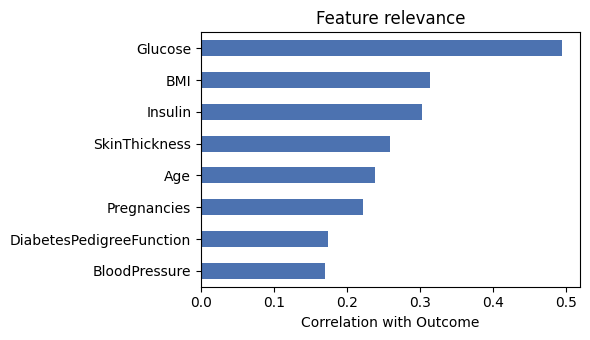

In [8]:
corr = df_clean.corr(numeric_only=True)["Outcome"].drop("Outcome").sort_values(ascending=False)
print("Correlation with Outcome (NaNs ignored pairwise):")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
corr.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Correlation with Outcome"); ax.invert_yaxis()
ax.set_title("Feature relevance")
plt.tight_layout(); plt.show()

**Why Glucose and BMI?**
- **Glucose** has the strongest correlation with `Outcome`; it is also clinically the most direct indicator of diabetes.
- **BMI** is a well-known, independent risk factor and has a relatively strong correlation.
- Both have **few missing values** (Glucose ≈ 0.7 %, BMI ≈ 1.4 %), unlike Insulin (≈ 49 %) and SkinThickness (≈ 30 %), so imputation has very little influence.
- They are only weakly correlated with each other, so they give two fairly distinct pieces of information for the plane.

In [9]:
FEATURES = ["Glucose", "BMI"]
TARGET = "Outcome"

X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print("Feature-to-feature correlation (Glucose vs BMI):",
      round(X["Glucose"].corr(X["BMI"]), 3))
print("Missing values in chosen features:\n", X.isna().sum(), sep="")

Feature-to-feature correlation (Glucose vs BMI): 0.233
Missing values in chosen features:
Glucose     5
BMI        11
dtype: int64


## 4. Stratified 80/20 Train/Test Split

The split is done **before** imputation and scaling. This ordering is the key to avoiding leakage:
the test set must remain "unseen" until the final evaluation.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
split_summary = pd.DataFrame({
    "full":  y.value_counts(normalize=True).sort_index(),
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test":  y_test.value_counts(normalize=True).sort_index(),
}).round(3)
print("\nClass proportions (stratification check):")
print(split_summary)
print("\nMissing in train:", X_train.isna().sum().to_dict())
print("Missing in test: ", X_test.isna().sum().to_dict())

Train shape: (614, 2) | Test shape: (154, 2)

Class proportions (stratification check):
          full  train   test
Outcome                     
0        0.651  0.651  0.649
1        0.349  0.349  0.351

Missing in train: {'Glucose': 4, 'BMI': 9}
Missing in test:  {'Glucose': 1, 'BMI': 2}


## 5. Impute Missing Values — Training Statistics Only

We use the **median** (robust to the skew in Glucose/BMI). The imputer is **fit on the training set only**
and then **applied** to both train and test.

In [11]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)                       # statistics learned from TRAIN only

print("Training medians used for imputation:")
print(dict(zip(FEATURES, map(float, imputer.statistics_.round(3)))))

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=FEATURES, index=X_test.index)

print("\nMissing after imputation -> train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))

Training medians used for imputation:
{'Glucose': 117.0, 'BMI': 32.4}

Missing after imputation -> train: 0 | test: 0


## 6. Standardize — Training Statistics Only

Standardization: $z = (x - \mu_{train}) / \sigma_{train}$.
Glucose (~100) and BMI (~30) live on very different scales; without scaling, gradient descent for Logistic
Regression would converge slowly and the perceptron updates would be dominated by the larger-scale feature.

In [12]:
scaler = StandardScaler()
scaler.fit(X_train_imp)                    # mean/std learned from TRAIN only

print("Training mean :", dict(zip(FEATURES, map(float, scaler.mean_.round(3)))))
print("Training std  :", dict(zip(FEATURES, map(float, scaler.scale_.round(3)))))

X_train_sc = scaler.transform(X_train_imp)
X_test_sc  = scaler.transform(X_test_imp)

y_train_arr = y_train.to_numpy().astype(int)
y_test_arr  = y_test.to_numpy().astype(int)

Training mean : {'Glucose': 121.671, 'BMI': 32.448}
Training std  : {'Glucose': 29.979, 'BMI': 6.819}


## 7. Verification of the Prepared Data

In [13]:
print("X_train_sc:", X_train_sc.shape, "| X_test_sc:", X_test_sc.shape)
print("y_train   :", y_train_arr.shape, "| y_test   :", y_test_arr.shape)
print()
print("Train mean (should be ~0):", X_train_sc.mean(axis=0).round(6))
print("Train std  (should be ~1):", X_train_sc.std(axis=0).round(6))
print("Test  mean (NOT exactly 0, that is expected):", X_test_sc.mean(axis=0).round(3))
print("Test  std  (NOT exactly 1, that is expected):", X_test_sc.std(axis=0).round(3))

assert not np.isnan(X_train_sc).any() and not np.isnan(X_test_sc).any()
assert set(np.unique(y_train_arr)) <= {0, 1}
assert np.allclose(X_train_sc.mean(axis=0), 0, atol=1e-8)
print("\nAll checks passed.")

X_train_sc: (614, 2) | X_test_sc: (154, 2)
y_train   : (614,) | y_test   : (154,)

Train mean (should be ~0): [-0.  0.]
Train std  (should be ~1): [1. 1.]
Test  mean (NOT exactly 0, that is expected): [-0.002  0.006]
Test  std  (NOT exactly 1, that is expected): [1.071 1.038]

All checks passed.


The test set does **not** have exactly mean 0 / std 1. That is correct and desirable: it was transformed with
the training parameters, exactly as a new, unseen patient would be at deployment time.

### Visualize the prepared training data

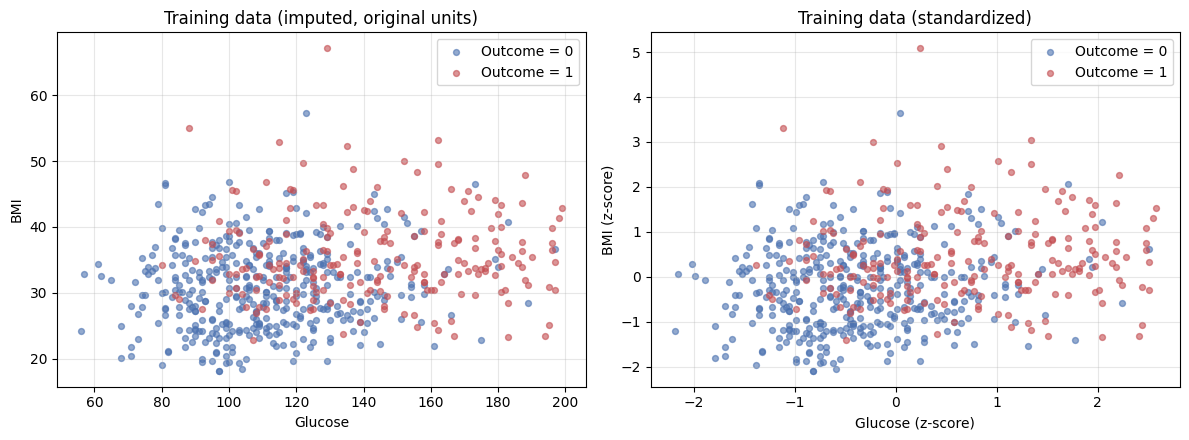

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# raw (imputed) space
for ax, data, title, xl, yl in [
    (axes[0], X_train_imp.to_numpy(), "Training data (imputed, original units)", "Glucose", "BMI"),
    (axes[1], X_train_sc,             "Training data (standardized)",            "Glucose (z-score)", "BMI (z-score)"),
]:
    ax.scatter(data[y_train_arr == 0, 0], data[y_train_arr == 0, 1], s=18, alpha=.6,
               c="#4C72B0", label="Outcome = 0")
    ax.scatter(data[y_train_arr == 1, 0], data[y_train_arr == 1, 1], s=18, alpha=.6,
               c="#C44E52", label="Outcome = 1")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title)
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

The two classes overlap considerably, so we should **not** expect perfect accuracy. The data is not perfectly
linearly separable, which matters for the perceptron: it is only guaranteed to converge on linearly separable data,
so on this dataset it will keep updating and needs a fixed epoch limit (Task 2).

## 8. Save the Prepared Data for Tasks 2–4

In [15]:
np.savez("prepared_diabetes_data.npz",
         X_train=X_train_sc, X_test=X_test_sc,
         y_train=y_train_arr, y_test=y_test_arr,
         features=np.array(FEATURES),
         train_mean=scaler.mean_, train_std=scaler.scale_,
         impute_medians=imputer.statistics_)
print("Saved prepared_diabetes_data.npz")

# In the next notebook you can simply do:
# d = np.load("prepared_diabetes_data.npz")
# X_train, X_test, y_train, y_test = d["X_train"], d["X_test"], d["y_train"], d["y_test"]

Saved prepared_diabetes_data.npz


## 9. Why Data Leakage Would Invalidate the Comparison

**Data leakage** means information from the test set influences the training pipeline, directly or indirectly.

**Where leakage could happen here**

| Mistake | What leaks | Consequence |
|---|---|---|
| Computing the median for imputation on the *full* dataset | Test-set values shift the fill value used in training | Training data "knows" about test patients |
| Fitting `StandardScaler` on the *full* dataset | Test mean and std enter the scaling of every sample | Feature geometry (and so the decision boundary) is shaped by test data |
| Scaling/imputing first, then splitting | Same as above, hidden by ordering | Same |
| Choosing features, thresholds or hyper-parameters by looking at test performance | Test labels guide model design | Test set is no longer independent |

**Why this invalidates the comparison**

1. **Optimistic, biased metrics.** The test score no longer measures performance on genuinely new patients, so the reported accuracy, precision and recall are inflated.
2. **Unequal, unreliable ranking.** Leakage may help one model more than the other. Perceptron updates are sensitive to feature scale, while Logistic Regression is smoother. The ranking of the two models could therefore reflect the leakage rather than their real ability, and we would not be comparing the algorithms fairly.
3. **Broken deployment assumption.** In real screening, a new patient's data is not available when the scaler and imputer are built. The pipeline must be reproducible using training information only.

**How this notebook prevents it**

- Split first (stratified, `random_state=42`).
- `SimpleImputer` and `StandardScaler` are `fit` on the training set only and merely `transform` the test set.
- Both models in Tasks 2–3 will use the *same* prepared arrays, so any difference in results comes from the algorithms and not from the data preparation.

## Summary of Task 1

| Item | Choice |
|---|---|
| Dataset | Pima Indians Diabetes (`diabetes.csv`), 768 rows |
| Target | `Outcome` (0/1), ≈ 65 % / 35 %, imbalanced |
| Invalid zeros | Glucose, BloodPressure, SkinThickness, Insulin, BMI → `NaN` |
| Predictors | **Glucose** and **BMI** (strong signal, few missing values, plottable in 2-D) |
| Split | Stratified 80/20, `random_state=42` → 614 train / 154 test |
| Imputation | Median, fit on training data only |
| Scaling | `StandardScaler`, fit on training data only |
| Output | `prepared_diabetes_data.npz` for Tasks 2, 3 and 4 |